# Multi-Head Latent Attention (MLA): shrinking the KV cache with a low-rank latent

Multi-Head Latent Attention was introduced in **DeepSeek-V2** (2024) and is the attention used in DeepSeek-V3, Kimi K2, and the full-attention layers of Kimi Linear.

During generation, a transformer has to keep every past token's keys and values around (the **KV cache**), and reading that cache back for every new token is what makes long-context decoding slow and memory-hungry. MLA changes *what* gets cached:

* Standard multi-head attention caches a key and a value **per head** for every token: $2 \cdot n_h \cdot d_h$ numbers per token per layer.
* MLA caches a single small **latent vector** $c_t^{KV}$ (plus one small shared positional key) per token, and recovers all of the per-head keys and values from it with up-projections.

The surprising part is that at inference time MLA **never actually rebuilds the keys and values**. The up-projections can be folded ("absorbed") into the query and output projections, so attention runs directly against the compressed cache.

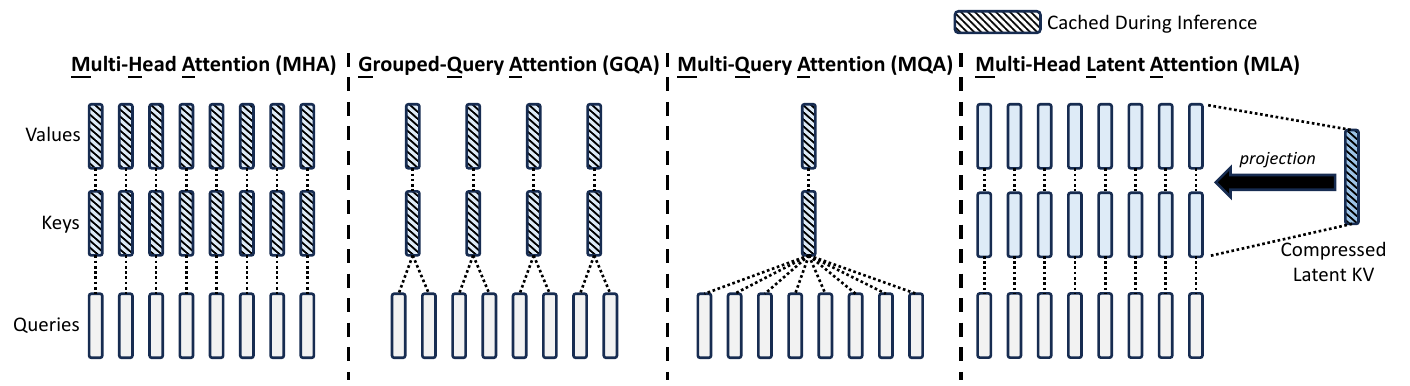

*DeepSeek-V2, Figure 3: what each attention variant caches (hatched). MHA caches every head's key and value. GQA and MQA shrink the cache by **sharing** keys and values across heads. MLA keeps a distinct key and value per head, but caches only the compressed latent they are all projected from. Source: [DeepSeek-V2, arXiv:2405.04434](https://arxiv.org/abs/2405.04434).*

We will build MLA from scratch in the following steps:
1. Why decoding is bottlenecked by the KV cache (with the actual numbers for DeepSeek-V3)
2. Evidence from a real model that keys and values are low-rank
3. Recap: MHA → GQA → MQA in one module
4. Low-rank joint KV compression
5. Weight absorption: attending directly to the latent
6. Why RoPE breaks absorption, and the fix: decoupled RoPE
7. The full MLA module, with three inference paths that we verify against each other
8. Decode cost: memory traffic versus FLOPs
9. Parameter counts at DeepSeek-V3 scale
10. MLA in production models (DeepSeek-V2/V3, Kimi K2, Kimi Linear)

Prerequisites in this repo: `09_multi_head_attention.ipynb`, `12_rotary_positional_embeddings.ipynb`, `11_layer_normalization.ipynb`.

### References
* DeepSeek-V2: A Strong, Economical, and Efficient Mixture-of-Experts Language Model: https://arxiv.org/abs/2405.04434 (MLA is §2.1, Table 1, Appendix C)
* DeepSeek-V3 Technical Report: https://arxiv.org/abs/2412.19437 (§2.1.1)
* DeepSeek-V3 official inference code (`inference/model.py`, class `MLA`): https://github.com/deepseek-ai/DeepSeek-V3
* Kimi Linear: An Expressive, Efficient Attention Architecture (uses MLA with NoPE): https://arxiv.org/abs/2510.26692
* Kimi K2 config: https://huggingface.co/moonshotai/Kimi-K2-Instruct

In [1]:
import math
import time
import inspect
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

torch.manual_seed(0)
device = torch.device("cpu")  # everything in this notebook runs comfortably on a laptop CPU

# ---- Plot style shared by every figure in this notebook ----
# Categorical colors are assigned in a fixed order (never cycled), grids are recessive,
# lines are thin, and series are direct-labeled where it helps.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = PALETTE
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#9a9893"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "xtick.color": INK_2, "ytick.color": INK_2,
    "lines.linewidth": 2, "lines.markersize": 6, "legend.frameon": False, "font.size": 10,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
})

# 1. Why decoding is bottlenecked by the KV cache

When a decoder-only model generates token $t$, the attention for that token needs the keys and values of **every previous token** $j \le t$:

$$o_{t,i} = \sum_{j=1}^{t} \text{Softmax}_j\left(\frac{q_{t,i}^\top k_{j,i}}{\sqrt{d_h}}\right) v_{j,i}$$

Recomputing $k_j, v_j$ for the whole prefix at every step would cost $O(t)$ projections per token, so every inference engine **caches** them. The cache grows linearly with context length, and it has two costs:

* **Memory capacity.** The cache for one sequence can be larger than the model weights. Whatever it occupies cannot be used for a bigger batch, so it directly limits throughput.
* **Memory bandwidth.** Each decoding step reads the *entire* cache from HBM to produce *one* token, doing only ~2 FLOPs per number read. Decoding attention is therefore memory-bound: its speed is set by how many bytes the cache occupies, not by how many FLOPs the GPU can do.

DeepSeek-V2 (Table 1) compares the cache size per token per layer of each attention variant. With $n_h$ heads of size $d_h$, $n_g$ KV groups, a latent of size $d_c$ and a decoupled RoPE key of size $d_h^R$:

| Attention | KV cache per token per layer (# elements) |
|---|---|
| Multi-Head Attention (MHA) | $2 n_h d_h$ |
| Grouped-Query Attention (GQA) | $2 n_g d_h$ |
| Multi-Query Attention (MQA) | $2 d_h$ |
| **Multi-Head Latent Attention (MLA)** | $d_c + d_h^R$ |

Let's put real numbers on this using the DeepSeek-V3 attention shape: 61 layers, $n_h = 128$ heads, $d_h = 128$, $d_c = 512$, $d_h^R = 64$ (from the V3 paper §4.2 and its `config.json`). The GQA row uses 8 KV groups, a common choice (e.g. Llama-3-70B), as a hypothetical comparison point.

In [2]:
def kv_cache_elements_per_token_per_layer(scheme: str, n_heads: int = 128, head_dim: int = 128,
                                          n_groups: int = 8, d_c: int = 512, d_rope: int = 64) -> int:
    """Number of cached elements for ONE token in ONE layer (DeepSeek-V2, Table 1)."""
    if scheme == "MHA":
        return 2 * n_heads * head_dim      # a key and a value per head
    if scheme == "GQA":
        return 2 * n_groups * head_dim     # a key and a value per group of heads
    if scheme == "MQA":
        return 2 * head_dim                # one key and one value shared by all heads
    if scheme == "MLA":
        return d_c + d_rope                # one latent + one shared RoPE key
    raise ValueError(scheme)

# DeepSeek-V3 attention shape (paper section 4.2 / config.json)
N_LAYERS, N_HEADS, HEAD_DIM, D_C, D_ROPE = 61, 128, 128, 512, 64
BYTES_PER_ELEMENT = 2  # bf16

schemes = ["MHA", "GQA", "MQA", "MLA"]
per_layer = {s: kv_cache_elements_per_token_per_layer(s, N_HEADS, HEAD_DIM, 8, D_C, D_ROPE) for s in schemes}

print(f"{'scheme':<6} {'elements/token/layer':>22} {'KB/token (61 layers, bf16)':>28} {'equivalent GQA groups':>23}")
for s in schemes:
    kb = per_layer[s] * N_LAYERS * BYTES_PER_ELEMENT / 1024
    print(f"{s:<6} {per_layer[s]:>22,} {kb:>28,.1f} {per_layer[s] / (2 * HEAD_DIM):>23.2f}")

scheme   elements/token/layer   KB/token (61 layers, bf16)   equivalent GQA groups
MHA                    32,768                      3,904.0                  128.00
GQA                     2,048                        244.0                    8.00
MQA                       256                         30.5                    1.00
MLA                       576                         68.6                    2.25


The last column reproduces DeepSeek-V2's claim that MLA's cache *"is equal to GQA with only 2.25 groups"*: $(d_c + d_h^R) / (2 d_h) = 576 / 256 = 2.25$. (V2 used the same $d_c = 4 d_h$ and $d_h^R = d_h/2$.)

Two figures make the scale concrete. The left panel is the per-token, per-layer cache. The right panel is the total cache for **one** sequence as the context grows, compared with the 80 GB of HBM on a single H100/A100-80GB.

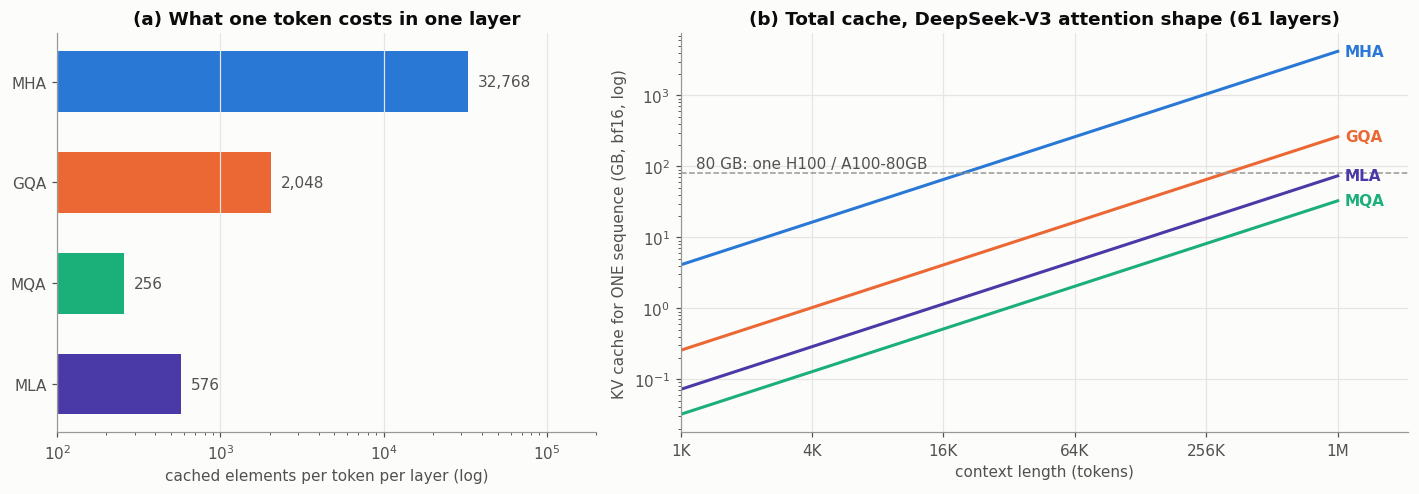

MHA:    524.0 GB at 128K context
GQA:     32.7 GB at 128K context
MQA:      4.1 GB at 128K context
MLA:      9.2 GB at 128K context


In [3]:
contexts = torch.logspace(math.log10(1_024), math.log10(1_048_576), 60)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.35]})

# (a) per-token, per-layer cache
colors = {"MHA": BLUE, "GQA": ORANGE, "MQA": AQUA, "MLA": VIOLET}
ypos = range(len(schemes))[::-1]
ax1.barh(list(ypos), [per_layer[s] for s in schemes], color=[colors[s] for s in schemes], height=0.6)
for y, s in zip(ypos, schemes):
    ax1.text(per_layer[s] * 1.15, y, f"{per_layer[s]:,}", va="center", color=INK_2)
ax1.set_yticks(list(ypos), schemes)
ax1.set_xscale("log"); ax1.set_xlim(100, 200_000)
ax1.set_xlabel("cached elements per token per layer (log)")
ax1.set_title("(a) What one token costs in one layer")
ax1.grid(axis="y", visible=False)

# (b) total cache for one sequence vs context
for s in schemes:
    gb = per_layer[s] * N_LAYERS * BYTES_PER_ELEMENT * contexts / 1e9
    ax2.plot(contexts, gb, color=colors[s])
    ax2.text(contexts[-1] * 1.08, gb[-1], s, color=colors[s], va="center", fontweight="bold")
ax2.axhline(80, color=MUTED, linestyle="--", linewidth=1)
ax2.text(1_200, 95, "80 GB: one H100 / A100-80GB", color=INK_2)
ax2.set_xscale("log", base=2); ax2.set_yscale("log")
ax2.set_xlim(1_024, 2.2e6)
ax2.set_xticks([2**k for k in range(10, 21, 2)], ["1K", "4K", "16K", "64K", "256K", "1M"])
ax2.set_xlabel("context length (tokens)"); ax2.set_ylabel("KV cache for ONE sequence (GB, bf16, log)")
ax2.set_title("(b) Total cache, DeepSeek-V3 attention shape (61 layers)")
plt.tight_layout(); plt.show()

for s in schemes:
    print(f"{s}: {per_layer[s] * N_LAYERS * BYTES_PER_ELEMENT * 128 * 1024 / 1e9:8.1f} GB at 128K context")

With MHA, one 128K-token sequence needs more KV cache than several GPUs hold. MLA brings it down to under 10 GB, between MQA (4.1 GB, a single shared key/value head) and 8-group GQA (32.7 GB), while still giving every head its own keys and values. DeepSeek-V2 reports that, compared with DeepSeek 67B (a dense GQA model), it *"reduces the KV cache by 93.3%, and boosts the maximum generation throughput to 5.76 times"*.

The schematic below shows what is cached per token for a toy model with 8 heads. Each bar is one cached vector, and its height is proportional to its size.

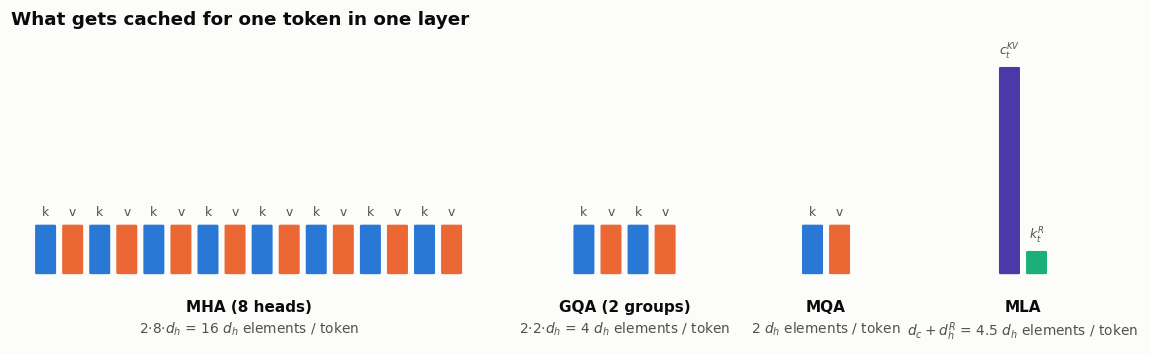

In [4]:
def draw_cache_layout(ax, x0, title, vectors, total):
    """vectors: list of (height, color, label) drawn as stacked columns."""
    x = x0
    for h, c, lab in vectors:
        ax.add_patch(FancyBboxPatch((x, 0), 0.32, h, boxstyle="round,pad=0,rounding_size=0.04",
                                    facecolor=c, edgecolor="#fcfcfb", linewidth=2))
        if lab:
            ax.text(x + 0.16, h + 0.08, lab, ha="center", va="bottom", fontsize=8, color=INK_2)
        x += 0.36
    ax.text(x0 + (x - x0) / 2 - 0.02, -0.45, title, ha="center", va="top", fontsize=10, fontweight="bold", color=INK)
    ax.text(x0 + (x - x0) / 2 - 0.02, -0.85, f"{total} elements / token", ha="center", va="top", fontsize=9, color=INK_2)
    return x

fig, ax = plt.subplots(figsize=(13, 3.6))
d_h = 1.0   # one head's key (or value) = height 1
x = 0
x = draw_cache_layout(ax, x, "MHA (8 heads)", [(d_h, BLUE, "k"), (d_h, ORANGE, "v")] * 8, "2·8·$d_h$ = 16 $d_h$") + 1.4
x = draw_cache_layout(ax, x, "GQA (2 groups)", [(d_h, BLUE, "k"), (d_h, ORANGE, "v")] * 2, "2·2·$d_h$ = 4 $d_h$") + 1.6
x = draw_cache_layout(ax, x, "MQA", [(d_h, BLUE, "k"), (d_h, ORANGE, "v")], "2 $d_h$") + 1.9
x = draw_cache_layout(ax, x, "MLA", [(4 * d_h, VIOLET, "$c_t^{KV}$"), (0.5 * d_h, AQUA, "$k_t^R$")], "$d_c + d_h^R$ = 4.5 $d_h$")
ax.set_xlim(-0.3, x + 0.9); ax.set_ylim(-1.2, 4.6); ax.axis("off")
ax.set_title("What gets cached for one token in one layer", loc="left")
plt.show()

# 2. Is the KV cache actually low-rank? Evidence from a real model

MLA is a bet that the keys and values of all heads, stacked together, live close to a **much lower-dimensional subspace** than $n_h d_h$. We can test this directly on a trained model that was *not* built with MLA.

Below we run `Qwen3-0.6B` (28 layers; GQA with 8 KV heads of size 128, so each layer's stacked keys are 1024-dimensional and so are its values) over about 2K tokens of English prose taken from Python's standard-library docstrings. We capture the output of every layer's `k_proj` and `v_proj` (before RoPE and the per-head norm) and compute the singular values of the resulting $T \times 1024$ matrices.

If $\sigma_1 \ge \sigma_2 \ge \dots$ are the singular values, the fraction of "energy" captured by the best rank-$r$ approximation is $\sum_{i\le r}\sigma_i^2 / \sum_i \sigma_i^2$ (Eckart–Young). If a small $r$ captures most of the energy, a low-rank latent can represent the cache well.

This cell needs the model weights in the local Hugging Face cache. It is skipped otherwise, and nothing later in the notebook depends on it.

In [5]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")
import argparse, json, logging, unittest, collections, functools, itertools, statistics, textwrap, typing, string, csv, email, asyncio, inspect as _inspect

def docstring_corpus() -> str:
    """English prose from standard-library docstrings (module docs plus their public classes and functions)."""
    chunks = []
    for mod in [argparse, json, logging, unittest, collections, functools, itertools, statistics, textwrap, typing, string, csv, email, asyncio, _inspect]:
        if mod.__doc__:
            chunks.append(mod.__doc__)
        for name in sorted(dir(mod)):
            obj = getattr(mod, name, None)
            if not name.startswith("_") and (_inspect.isclass(obj) or _inspect.isfunction(obj)) and isinstance(obj.__doc__, str):
                chunks.append(obj.__doc__)
    return "\n\n".join(chunks)

def energy_curve(x: torch.Tensor) -> torch.Tensor:
    """Cumulative fraction of squared singular values: energy captured by the best rank-r approximation."""
    s = torch.linalg.svdvals(x.double())
    e = s.pow(2)
    return (e.cumsum(0) / e.sum()).float()

def rank_for(curve: torch.Tensor, frac: float) -> int:
    """Smallest rank r whose best rank-r approximation captures `frac` of the energy."""
    return int((curve < frac).sum().item()) + 1

lowrank = None
try:
    from transformers import AutoModelForCausalLM, AutoTokenizer
    MODEL = "Qwen/Qwen3-0.6B"
    tok = AutoTokenizer.from_pretrained(MODEL, local_files_only=True)
    lm = AutoModelForCausalLM.from_pretrained(MODEL, local_files_only=True, torch_dtype=torch.float32).eval()
    cfg = lm.config
    print(f"{MODEL}: {cfg.num_hidden_layers} layers, {cfg.num_attention_heads} query heads, "
          f"{cfg.num_key_value_heads} KV heads x head_dim {cfg.head_dim} -> k_proj/v_proj width {cfg.num_key_value_heads * cfg.head_dim}")

    ids = tok(docstring_corpus(), return_tensors="pt").input_ids[:, :2048]
    captured = {"k": {}, "v": {}}
    hooks = []
    for i, layer in enumerate(lm.model.layers):
        hooks.append(layer.self_attn.k_proj.register_forward_hook(lambda m, inp, out, i=i: captured["k"].__setitem__(i, out[0])))
        hooks.append(layer.self_attn.v_proj.register_forward_hook(lambda m, inp, out, i=i: captured["v"].__setitem__(i, out[0])))
    with torch.no_grad():
        lm(ids)
    for h in hooks:
        h.remove()

    L = cfg.num_hidden_layers
    lowrank = {
        "K": [energy_curve(captured["k"][i]) for i in range(L)],
        "V": [energy_curve(captured["v"][i]) for i in range(L)],
        "[K;V] jointly": [energy_curve(torch.cat([captured["k"][i], captured["v"][i]], -1)) for i in range(L)],
    }
    print(f"tokens analysed: {ids.shape[1]}")
    del lm
except Exception as e:  # model not cached, no internet, etc.
    print("Skipping the real-model analysis:", repr(e)[:200])

Qwen/Qwen3-0.6B: 28 layers, 16 query heads, 8 KV heads x head_dim 128 -> k_proj/v_proj width 1024


tokens analysed: 2048


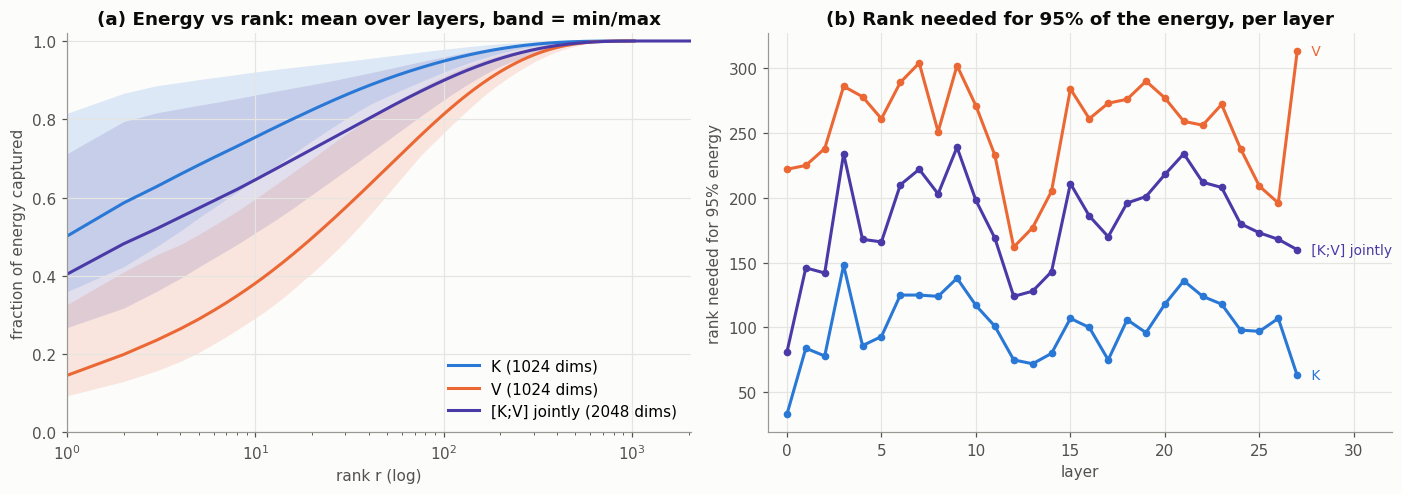

             K: rank for 90% energy -> median     50 of 1024 dims ( 4.9%), worst layer    79
             K: rank for 95% energy -> median    100 of 1024 dims ( 9.8%), worst layer   148
             K: rank for 99% energy -> median    273 of 1024 dims (26.7%), worst layer   344
             V: rank for 90% energy -> median    175 of 1024 dims (17.1%), worst layer   211
             V: rank for 95% energy -> median    261 of 1024 dims (25.5%), worst layer   313
             V: rank for 99% energy -> median    464 of 1024 dims (45.3%), worst layer   535
 [K;V] jointly: rank for 90% energy -> median    106 of 2048 dims ( 5.2%), worst layer   146
 [K;V] jointly: rank for 95% energy -> median    180 of 2048 dims ( 8.8%), worst layer   239
 [K;V] jointly: rank for 99% energy -> median    428 of 2048 dims (20.9%), worst layer   502


In [6]:
if lowrank is not None:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))
    series_colors = {"K": BLUE, "V": ORANGE, "[K;V] jointly": VIOLET}
    for name, curves in lowrank.items():
        C = torch.stack(curves)                   # (layers, dims)
        dims = C.shape[1]
        r = torch.arange(1, dims + 1)
        ax1.plot(r, C.mean(0), color=series_colors[name], label=f"{name} ({dims} dims)")
        ax1.fill_between(r, C.min(0).values, C.max(0).values, color=series_colors[name], alpha=0.15, linewidth=0)
    ax1.set_xscale("log"); ax1.set_ylim(0, 1.02); ax1.set_xlim(1, 2048); ax1.legend(loc="lower right")
    ax1.set_xlabel("rank r (log)"); ax1.set_ylabel("fraction of energy captured")
    ax1.set_title("(a) Energy vs rank: mean over layers, band = min/max")

    for name, curves in lowrank.items():
        ranks = [rank_for(c, 0.95) for c in curves]
        ax2.plot(range(len(ranks)), ranks, marker="o", markersize=4, color=series_colors[name])
        ax2.text(len(ranks) - 0.5, ranks[-1], f" {name}", color=series_colors[name], va="center", fontsize=9)
    ax2.set_xlabel("layer"); ax2.set_ylabel("rank needed for 95% energy")
    ax2.set_title("(b) Rank needed for 95% of the energy, per layer")
    ax2.set_xlim(-1, len(ranks) + 4)
    plt.tight_layout(); plt.show()

    for name, curves in lowrank.items():
        dims = curves[0].numel()
        for frac in (0.90, 0.95, 0.99):
            rs = torch.tensor([rank_for(c, frac) for c in curves]).float()
            print(f"{name:>14}: rank for {frac:.0%} energy -> median {rs.median():6.0f} of {dims} dims "
                  f"({rs.median() / dims:5.1%}), worst layer {rs.max():5.0f}")

**How to read this** (numbers refer to the run saved in this notebook):
* The spectrum falls off steeply in **every** layer. Jointly, the 2048 stacked key+value dimensions need a median rank of about 180 for 95% of the energy and about 430 for 99%. Even the worst layer stays near 500, which is roughly DeepSeek's choice of $d_c = 512$.
* **Keys are much more compressible than values.** About 100 dimensions hold 95% of the key energy, against about 260 for values.
* Stacking K and V and compressing them **together** costs far less than the two separately, because they share a lot of structure. That is the case for MLA's *joint* latent.

Qwen3 was never trained to be low-rank (and its GQA cache is already 8× smaller than full MHA), yet the structure is there. MLA does not compress a trained cache after the fact. It **trains the bottleneck in from the start** ($d_c = 512$ against $2 n_h d_h = 32{,}768$ for DeepSeek-V3), so the model learns to use the latent space as well as it can.

Two caveats keep this honest:
* Energy is not the same as accuracy. Attention logits pass through a softmax, and a small residual can still matter. That is why MLA learns the bottleneck instead of truncating an SVD.
* The numbers depend on the text and on the token count. With $T$ tokens the rank can never exceed $\min(T, d)$. With $T = 2048$, the 1024-dim K and V matrices are not limited by the token count. For the 2048-dim joint matrix the bound is exactly tight ($T = d$), but even the worst layer needs only ~500 dimensions for 99% of the energy, far below it.

# 3. Recap: MHA → GQA → MQA in one module

Before compressing anything, here is the baseline family as one from-scratch module. The only knob is `n_kv_heads`:
* `n_kv_heads == n_heads`: **MHA**. Every head has its own key and value.
* `1 < n_kv_heads < n_heads`: **GQA**. Groups of query heads share one key/value head.
* `n_kv_heads == 1`: **MQA**. All heads share a single key/value head.

GQA and MQA shrink the cache by **sharing** keys and values across heads, which forces heads in a group to look at exactly the same keys. MLA takes a different route: every head still gets its **own** key and value, but they are all generated from one shared low-dimensional latent.

In [7]:
class GroupedQueryAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int, n_kv_heads: int, head_dim: int):
        """
        MHA / GQA / MQA depending on n_kv_heads.

        Args:
            d_model (int): model (residual stream) width.
            n_heads (int): number of query heads.
            n_kv_heads (int): number of key/value heads (must divide n_heads).
            head_dim (int): width of each head.
        """
        super().__init__()
        assert n_heads % n_kv_heads == 0, "n_heads must be a multiple of n_kv_heads"
        self.n_heads, self.n_kv_heads, self.head_dim = n_heads, n_kv_heads, head_dim
        self.wq = nn.Linear(d_model, n_heads * head_dim, bias=False)
        self.wk = nn.Linear(d_model, n_kv_heads * head_dim, bias=False)
        self.wv = nn.Linear(d_model, n_kv_heads * head_dim, bias=False)
        self.wo = nn.Linear(n_heads * head_dim, d_model, bias=False)

    def cache_elements_per_token(self) -> int:
        # one key and one value per KV head
        return 2 * self.n_kv_heads * self.head_dim

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, T, _ = x.shape
        # (B, T, d_model) -> (B, T, heads, head_dim)
        q = self.wq(x).view(B, T, self.n_heads, self.head_dim)
        k = self.wk(x).view(B, T, self.n_kv_heads, self.head_dim)
        v = self.wv(x).view(B, T, self.n_kv_heads, self.head_dim)
        # Each KV head serves n_heads / n_kv_heads query heads: (B, T, n_kv, hd) -> (B, T, n_heads, hd)
        repeat = self.n_heads // self.n_kv_heads
        k, v = k.repeat_interleave(repeat, dim=2), v.repeat_interleave(repeat, dim=2)
        # scores: (B, heads, T_query, T_key)
        scores = torch.einsum("bshd,bthd->bhst", q, k) / math.sqrt(self.head_dim)
        causal = torch.ones(T, T, dtype=torch.bool).triu(1)
        probs = scores.masked_fill(causal, float("-inf")).softmax(-1)
        out = torch.einsum("bhst,bthd->bshd", probs, v)       # (B, T, heads, head_dim)
        return self.wo(out.reshape(B, T, -1))                 # (B, T, d_model)

x = torch.randn(2, 10, 512)
for name, n_kv in [("MHA", 8), ("GQA", 2), ("MQA", 1)]:
    attn = GroupedQueryAttention(d_model=512, n_heads=8, n_kv_heads=n_kv, head_dim=64)
    print(f"{name}: output {tuple(attn(x).shape)}, cached elements per token per layer = {attn.cache_elements_per_token()}")

MHA: output (2, 10, 512), cached elements per token per layer = 1024
GQA: output (2, 10, 512), cached elements per token per layer = 256
MQA: output (2, 10, 512), cached elements per token per layer = 128


# 4. Low-rank joint KV compression

MLA replaces the key and value projections with a **down-projection** to a small latent, followed by **up-projections** back to per-head keys and values (DeepSeek-V2, Eq. 9–11):

$$c_t^{KV} = W^{DKV} h_t, \qquad k_t^C = W^{UK} c_t^{KV}, \qquad v_t^C = W^{UV} c_t^{KV}$$

| symbol | shape | meaning |
|---|---|---|
| $h_t$ | $d$ | input hidden state of token $t$ |
| $W^{DKV}$ | $d_c \times d$ | down-projection, shared by keys **and** values ("joint" compression) |
| $c_t^{KV}$ | $d_c$ | **the latent: the only thing cached** (DeepSeek-V2/V3: $d_c = 512$) |
| $W^{UK}, W^{UV}$ | $n_h d_h \times d_c$ | up-projections to all heads' keys / values |

Two consequences follow directly from the algebra:
1. The effective key projection is $W^K_{\text{eff}} = W^{UK} W^{DKV}$, a $n_h d_h \times d$ matrix of **rank at most $d_c$**. MLA is MHA whose key and value projections are constrained to share a $d_c$-dimensional row space.
2. Keys and values share the latent, so a single $d_c$-vector per token is enough to rebuild both.

The queries get the same treatment (Eq. 12–13), $c_t^Q = W^{DQ} h_t$ and $q_t^C = W^{UQ} c_t^Q$ with $d_c' = 1536$. This does **not** change the cache, because queries are never cached. DeepSeek-V3 notes it *"can reduce the activation memory during training"*. Both latents get an RMSNorm before their up-projection.

Let's check the rank claim numerically.

In [8]:
d_model, n_heads, head_dim, d_c = 512, 8, 64, 32

W_DKV = nn.Linear(d_model, d_c, bias=False)              # h_t -> c_t^KV       (d_c x d)
W_UK = nn.Linear(d_c, n_heads * head_dim, bias=False)    # c_t^KV -> k_t^C     (n_h d_h x d_c)
W_UV = nn.Linear(d_c, n_heads * head_dim, bias=False)    # c_t^KV -> v_t^C

h = torch.randn(2, 10, d_model)
c_kv = W_DKV(h)                                          # (2, 10, 32)   <- this is what we cache
k = W_UK(c_kv).view(2, 10, n_heads, head_dim)            # (2, 10, 8, 64)
v = W_UV(c_kv).view(2, 10, n_heads, head_dim)
print("latent:", tuple(c_kv.shape), " keys:", tuple(k.shape), " values:", tuple(v.shape))

W_K_eff = W_UK.weight @ W_DKV.weight                     # (n_h d_h, d) = (512, 512)
print(f"effective key projection {tuple(W_K_eff.shape)} has rank {torch.linalg.matrix_rank(W_K_eff).item()} (= d_c = {d_c})")
print(f"cache per token: MHA {2 * n_heads * head_dim} elements vs latent {d_c} elements "
      f"({2 * n_heads * head_dim / d_c:.0f}x smaller)")

latent: (2, 10, 32)  keys: (2, 10, 8, 64)  values: (2, 10, 8, 64)
effective key projection (512, 512) has rank 32 (= d_c = 32)
cache per token: MHA 1024 elements vs latent 32 elements (32x smaller)


# 5. Weight absorption: attending directly to the latent

If we cached $c^{KV}$ and rebuilt $k_j = W^{UK} c_j^{KV}$ for the whole prefix at every step, we would save memory but pay $O(t \cdot d_c \cdot n_h d_h)$ extra FLOPs per generated token. The point of MLA is that this reconstruction is **unnecessary**. DeepSeek-V2 (Appendix C): *"due to the associative law of matrix multiplication, we can absorb $W^{UK}$ into $W^{UQ}$, and $W^{UV}$ into $W^O$."*

**Keys.** For head $i$ (writing $W^{UK}_i \in \mathbb{R}^{d_h \times d_c}$ for that head's rows):

$$q_{t,i}^\top k_{j,i} \;=\; q_{t,i}^\top \big(W^{UK}_i c_j^{KV}\big) \;=\; \underbrace{\big(W^{UK\top}_i q_{t,i}\big)^\top}_{\tilde q_{t,i} \in \mathbb{R}^{d_c}} c_j^{KV}$$

So we map each head's query **into latent space** once per generated token and dot it with the cached latents directly. (Equivalently, $W^{UK\top}_i W^{UQ}_i$ can be pre-multiplied into a single matrix.)

**Values.** The attention output is a weighted sum, and $W^{UV}_i$ is linear:

$$o_{t,i} = \sum_j p_{t,j,i}\, W^{UV}_i c_j^{KV} = W^{UV}_i \Big(\sum_j p_{t,j,i}\, c_j^{KV}\Big)$$

So we average **latents** and apply $W^{UV}_i$ once at the end. Because $W^O$ follows immediately, $W^{UV}$ can even be merged into $W^O$.

In this form every head reads the **same** cached $c_j^{KV}$, which makes MLA at inference time a form of **multi-query attention** with key and value width $d_c$. Let's verify that both paths give the same numbers (ignoring RoPE for now).

In [9]:
torch.manual_seed(0)
T = 16
q = torch.randn(T, n_heads, head_dim)                                    # queries for T positions
W_uk = W_UK.weight.view(n_heads, head_dim, d_c)                          # per-head W^UK_i: (h, d_h, d_c)
W_uv = W_UV.weight.view(n_heads, head_dim, d_c)                          # per-head W^UV_i
C = W_DKV(torch.randn(T, d_model))                                       # cached latents (T, d_c)
causal = torch.ones(T, T, dtype=torch.bool).triu(1)

with torch.no_grad():
    # --- naive: rebuild per-head keys/values from the latent, then ordinary attention ---
    K = torch.einsum("hdc,tc->thd", W_uk, C)                             # (T, h, d_h)
    V = torch.einsum("hdc,tc->thd", W_uv, C)
    s_naive = torch.einsum("shd,thd->hst", q, K) / math.sqrt(head_dim)
    p = s_naive.masked_fill(causal, float("-inf")).softmax(-1)
    o_naive = torch.einsum("hst,thd->shd", p, V)

    # --- absorbed: move the query into latent space, attend to latents, up-project once ---
    q_lat = torch.einsum("shd,hdc->shc", q, W_uk)                        # (T, h, d_c)
    s_abs = torch.einsum("shc,tc->hst", q_lat, C) / math.sqrt(head_dim)
    p_abs = s_abs.masked_fill(causal, float("-inf")).softmax(-1)
    o_lat = torch.einsum("hst,tc->shc", p_abs, C)                        # weighted sum of LATENTS
    o_abs = torch.einsum("shc,hdc->shd", o_lat, W_uv)                    # one up-projection at the end

print(f"max |score difference|  = {(s_naive - s_abs).abs().max():.2e}")
print(f"max |output difference| = {(o_naive - o_abs).abs().max():.2e}")

max |score difference|  = 4.17e-07
max |output difference| = 1.79e-07


# 6. Why RoPE breaks absorption, and the fix: decoupled RoPE

Rotary position embeddings (see `12_rotary_positional_embeddings.ipynb`) rotate each query and key by a position-dependent orthogonal matrix $R_t$. The score between positions $t$ and $j$ becomes

$$\big(R_t q_t\big)^\top \big(R_j k_j\big) = q_t^\top R_{j-t}\, k_j,$$

which depends only on the relative offset $j - t$. Now plug in the latent key $k_j = W^{UK} c_j^{KV}$:

$$q_t^\top R_{j-t}\, W^{UK} c_j^{KV}.$$

A **position-dependent rotation now sits between the query and $W^{UK}$**. There is no single matrix to absorb, because the matrix changes with every offset. DeepSeek-V2 §2.1.3 puts it like this: *"a RoPE matrix related to the currently generating token will lie between $W^Q$ and $W^{UK}$ and matrix multiplication does not obey a commutative law. As a result, we must recompute the keys for all the prefix tokens during inference."*

**Decoupled RoPE** separates *content* from *position*. Each head's query and key get extra $d_h^R$ dimensions that carry RoPE, while the original $d_h$ dimensions stay rotation-free (Eq. 14–17):

$$q_{t,i} = [\,q^C_{t,i}\,;\; \text{RoPE}(W^{QR}_i c^Q_t)\,], \qquad k_{j,i} = [\,k^C_{j,i}\,;\; \underbrace{\text{RoPE}(W^{KR} h_j)}_{k^R_j \text{ shared by all heads}}\,]$$

$$q_{t,i}^\top k_{j,i} = \underbrace{q^{C\top}_{t,i}\, k^C_{j,i}}_{\text{absorbable (no rotation)}} + \underbrace{q^{R\top}_{t,i}\, k^R_j}_{\text{small, cached directly}}$$

The positional key $k^R_j$ is **one** $d_h^R = 64$-vector per token, shared across heads like MQA, and it is cached **already rotated**. That is where the cache size $d_c + d_h^R = 576$ comes from. The softmax scale becomes $1/\sqrt{d_h + d_h^R}$.

First, RoPE from scratch. Like the DeepSeek-V3 inference code, we rotate **adjacent pairs** $(x_{2m}, x_{2m+1})$ by angle $t\,\theta_m$ with $\theta_m = b^{-2m/d}$.

In [10]:
def rope_angles(dim: int, max_len: int, base: float = 10000.0):
    """cos/sin tables of shape (max_len, dim/2) for rotating adjacent pairs."""
    inv_freq = 1.0 / (base ** (torch.arange(0, dim, 2).float() / dim))   # theta_m, (dim/2,)
    angles = torch.outer(torch.arange(max_len).float(), inv_freq)        # t * theta_m, (max_len, dim/2)
    return angles.cos(), angles.sin()

def apply_rope(x: torch.Tensor, cos: torch.Tensor, sin: torch.Tensor) -> torch.Tensor:
    """
    Rotate adjacent pairs (x[2m], x[2m+1]) by angle t * theta_m.
    x: (B, T, H, dim)   cos/sin: (T, dim/2) for the T positions of x.
    """
    x_even, x_odd = x[..., 0::2], x[..., 1::2]                           # (B, T, H, dim/2) each
    cos, sin = cos[None, :, None, :], sin[None, :, None, :]
    rot_even = x_even * cos - x_odd * sin                                # 2x2 rotation of each pair
    rot_odd = x_even * sin + x_odd * cos
    return torch.stack([rot_even, rot_odd], dim=-1).flatten(-2)          # interleave back: (B, T, H, dim)

# Sanity check: RoPE scores depend only on the relative offset
cos, sin = rope_angles(64, 4096)
qv, kv_ = torch.randn(1, 1, 1, 64), torch.randn(1, 1, 1, 64)
def score_at(t, j):
    return (apply_rope(qv, cos[t:t + 1], sin[t:t + 1]) * apply_rope(kv_, cos[j:j + 1], sin[j:j + 1])).sum().item()
print(f"score(t=10, j=3) = {score_at(10, 3):.6f}   score(t=1010, j=1003) = {score_at(1010, 1003):.6f}")

score(t=10, j=3) = -10.443087   score(t=1010, j=1003) = -10.443030


Now the experiment behind the figure. For one head we compute the true RoPE score of a query at position $t$ against a latent key at position $j$, for many offsets $t - j$, and compare it with two absorbed computations:
* **Absorb, RoPE on the whole key** (what fails): pre-multiply the position-free $W^{UK}$ into the query, which silently drops the rotation $R_{j-t}$.
* **Decoupled RoPE**: absorb only the content part and add the separately cached rotated key.

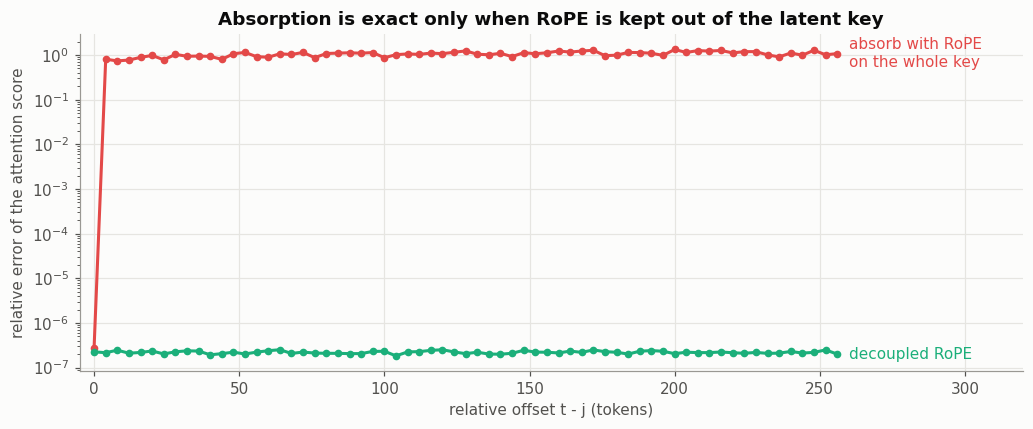

offset 0: full-RoPE absorb error 2.8e-07; at offset >= 4 it is 0.74-1.33. decoupled: max error 2.5e-07


In [11]:
torch.manual_seed(0)
d_h, d_hR, d_c_demo, n_trials = 64, 32, 128, 256
W_uk_i = torch.randn(d_h, d_c_demo) / math.sqrt(d_c_demo)       # one head's W^UK_i
W_kr = torch.randn(d_hR, d_model) / math.sqrt(d_model)          # W^KR (shared positional key)
cos_h, sin_h = rope_angles(d_h, 4096)
cos_r, sin_r = rope_angles(d_hR, 4096)
offsets = list(range(0, 257, 4))
err_full, err_decoupled = [], []

def rot(x, pos, cos, sin):  # rotate a batch of vectors x: (N, dim) as if all at position `pos`
    return apply_rope(x[None, :, None, :], cos[pos:pos + 1].expand(x.shape[0], -1), sin[pos:pos + 1].expand(x.shape[0], -1))[0, :, 0, :]

with torch.no_grad():
    for off in offsets:
        t, j = 1000 + off, 1000                                   # query at t, key at j = t - off
        qc = torch.randn(n_trials, d_h)                           # content query
        qr = torch.randn(n_trials, d_hR)                          # RoPE query part
        c = torch.randn(n_trials, d_c_demo)                       # latent of the key token
        h_j = torch.randn(n_trials, d_model)                      # hidden state of the key token

        # (1) RoPE applied to the whole latent-derived key: true score vs absorbed (rotation dropped)
        k_full = c @ W_uk_i.T
        true_full = (rot(qc, t, cos_h, sin_h) * rot(k_full, j, cos_h, sin_h)).sum(-1)
        absorbed_full = ((qc @ W_uk_i) * c).sum(-1)               # q^T W^UK c, no way to insert R_{j-t}
        err_full.append(((true_full - absorbed_full).abs().mean() / true_full.abs().mean()).item())

        # (2) Decoupled RoPE: rotation-free content part + separately rotated shared key
        k_rope = rot(h_j @ W_kr.T, j, cos_r, sin_r)               # cached already rotated
        true_dec = (qc * k_full).sum(-1) + (rot(qr, t, cos_r, sin_r) * k_rope).sum(-1)
        absorbed_dec = ((qc @ W_uk_i) * c).sum(-1) + (rot(qr, t, cos_r, sin_r) * k_rope).sum(-1)
        err_decoupled.append(((true_dec - absorbed_dec).abs().mean() / true_dec.abs().mean()).item())

fig, ax = plt.subplots(figsize=(9.5, 4))
ax.plot(offsets, err_full, color=RED, marker="o", markersize=4)
ax.plot(offsets, [max(e, 1e-9) for e in err_decoupled], color=AQUA, marker="o", markersize=4)
ax.text(offsets[-1] + 4, err_full[-1], "absorb with RoPE\non the whole key", color=RED, va="center")
ax.text(offsets[-1] + 4, max(err_decoupled[-1], 1e-9), "decoupled RoPE", color=AQUA, va="center")
ax.set_yscale("log"); ax.set_xlim(-5, 320)
ax.set_xlabel("relative offset t - j (tokens)"); ax.set_ylabel("relative error of the attention score")
ax.set_title("Absorption is exact only when RoPE is kept out of the latent key")
plt.tight_layout(); plt.show()
print(f"offset 0: full-RoPE absorb error {err_full[0]:.1e}; at offset >= 4 it is {min(err_full[1:]):.2f}-{max(err_full[1:]):.2f}. "
      f"decoupled: max error {max(err_decoupled):.1e}")

At offset 0 the rotations cancel ($R_0 = I$), so even the naive absorption is exact on the diagonal. At **every other offset** it is completely wrong: the error is of the same order as the score itself. With decoupled RoPE the absorbed score matches the true score to float32 precision at all offsets.

# 7. The full MLA module

Now we assemble everything. The parameter names follow DeepSeek's code (each fused matrix is listed with its paper symbol) so the mapping to the papers is easy to check:

| module | paper | shape (DeepSeek-V3) | role |
|---|---|---|---|
| `wq_a` | $W^{DQ}$ | $7168 \to 1536$ | query down-projection |
| `q_norm` | RMSNorm | $1536$ | norm on the query latent |
| `wq_b` | $[W^{UQ}; W^{QR}]$ | $1536 \to 128 \times (128 + 64)$ | per-head content query + RoPE query |
| `wkv_a` | $[W^{DKV}; W^{KR}]$ | $7168 \to 512 + 64$ | KV latent + shared RoPE key |
| `kv_norm` | RMSNorm | $512$ | norm on the KV latent (**applied before caching**) |
| `wkv_b` | $[W^{UK}; W^{UV}]$ | $512 \to 128 \times (128 + 128)$ | per-head content key + value |
| `wo` | $W^O$ | $128 \times 128 \to 7168$ | output projection |

Here is the paper's own picture of the module. Read it bottom-up: one latent $c_t^Q$ feeds all the query heads, and one latent $c_t^{KV}$ feeds all the content keys and values. The positional key $k_t^R$ comes straight from $h_t$ and is shared by every head. The hatched tensors are the cache.

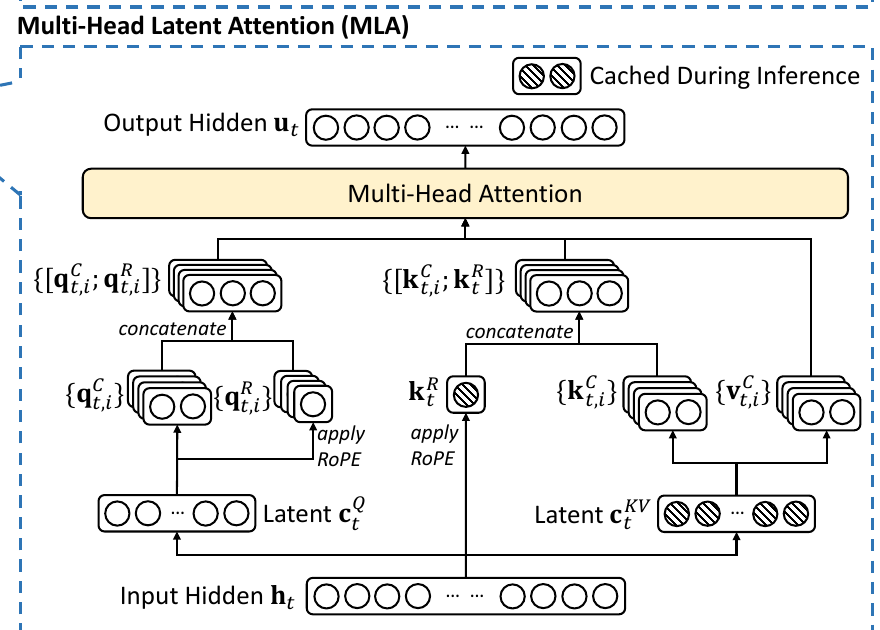

*DeepSeek-V2, Figure 2 (MLA panel). Source: [DeepSeek-V2, arXiv:2405.04434](https://arxiv.org/abs/2405.04434).*

Our own version of the same diagram, labelled with the module names used in the code below. The two highlighted tensors are the **only** things that go into the cache.

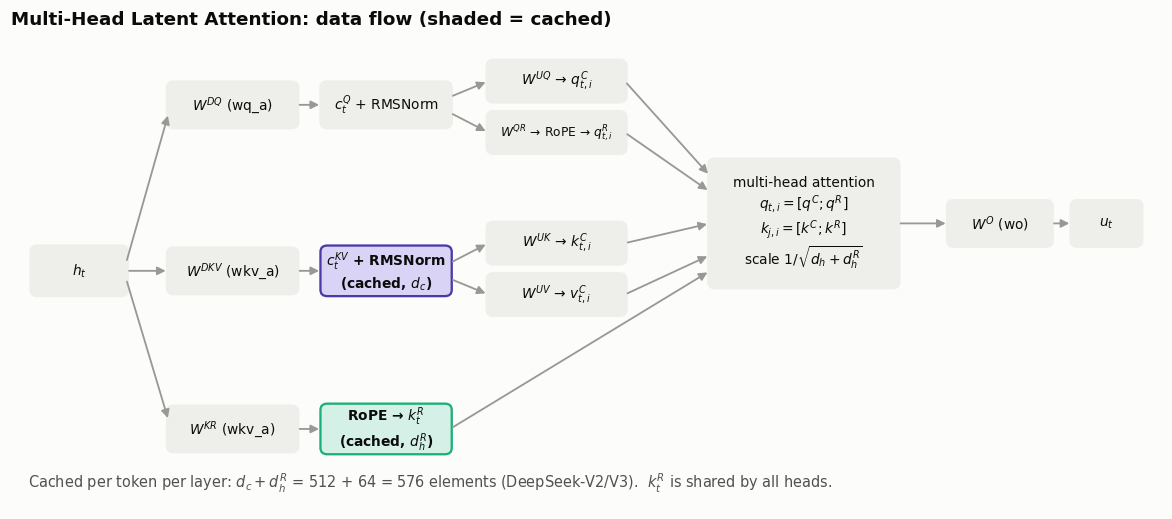

In [12]:
def box(ax, x, y, w, h, text, fc, ec=None, fontsize=9, bold=False, color=INK):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                facecolor=fc, edgecolor=ec or fc, linewidth=1.5))
    ax.text(x, y, text, ha="center", va="center", fontsize=fontsize, color=color, fontweight="bold" if bold else "normal")

def arrow(ax, p, q, color=MUTED, style="-|>", rad=0.0):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle=style, mutation_scale=11, color=color, linewidth=1.2,
                                 connectionstyle=f"arc3,rad={rad}", shrinkA=2, shrinkB=2))

LIGHT, CACHE = "#eeeeea", "#d9d4f5"
fig, ax = plt.subplots(figsize=(13.5, 5.6))
ax.set_xlim(0, 13.5); ax.set_ylim(0, 6); ax.axis("off")

box(ax, 0.8, 3.0, 1.1, 0.6, "$h_t$", LIGHT, bold=True)
# query path (top)
box(ax, 2.6, 5.1, 1.5, 0.55, "$W^{DQ}$ (wq_a)", LIGHT)
box(ax, 4.4, 5.1, 1.5, 0.55, "$c_t^{Q}$ + RMSNorm", LIGHT)
box(ax, 6.4, 5.4, 1.6, 0.5, "$W^{UQ}$ → $q^C_{t,i}$", LIGHT)
box(ax, 6.4, 4.75, 1.6, 0.5, "$W^{QR}$ → RoPE → $q^R_{t,i}$", LIGHT, fontsize=8)
# kv path (middle)
box(ax, 2.6, 3.0, 1.5, 0.55, "$W^{DKV}$ (wkv_a)", LIGHT)
box(ax, 4.4, 3.0, 1.5, 0.6, "$c_t^{KV}$ + RMSNorm\n(cached, $d_c$)", CACHE, ec=VIOLET, bold=True)
box(ax, 6.4, 3.35, 1.6, 0.5, "$W^{UK}$ → $k^C_{t,i}$", LIGHT)
box(ax, 6.4, 2.7, 1.6, 0.5, "$W^{UV}$ → $v^C_{t,i}$", LIGHT)
# rope key path (bottom)
box(ax, 2.6, 1.0, 1.5, 0.55, "$W^{KR}$ (wkv_a)", LIGHT)
box(ax, 4.4, 1.0, 1.5, 0.6, "RoPE → $k_t^R$\n(cached, $d_h^R$)", "#d5f0e6", ec=AQUA, bold=True)
# attention + output
box(ax, 9.3, 3.6, 2.2, 1.6, "multi-head attention\n$q_{t,i}=[q^C;q^R]$\n$k_{j,i}=[k^C;k^R]$\nscale $1/\\sqrt{d_h+d_h^R}$", LIGHT, fontsize=9)
box(ax, 11.6, 3.6, 1.2, 0.55, "$W^O$ (wo)", LIGHT)
box(ax, 12.85, 3.6, 0.8, 0.55, "$u_t$", LIGHT, bold=True)

for p, q_ in [((1.35, 3.1), (1.85, 5.0)), ((1.35, 3.0), (1.85, 3.0)), ((1.35, 2.9), (1.85, 1.1)),
              ((3.35, 5.1), (3.65, 5.1)), ((5.15, 5.2), (5.6, 5.4)), ((5.15, 5.0), (5.6, 4.75)),
              ((3.35, 3.0), (3.65, 3.0)), ((5.15, 3.1), (5.6, 3.35)), ((5.15, 2.9), (5.6, 2.7)),
              ((3.35, 1.0), (3.65, 1.0)),
              ((7.2, 5.4), (8.2, 4.2)), ((7.2, 4.75), (8.2, 4.0)), ((7.2, 3.35), (8.2, 3.6)), ((7.2, 2.7), (8.2, 3.2)),
              ((5.15, 1.0), (8.2, 3.0)), ((10.4, 3.6), (11.0, 3.6)), ((12.2, 3.6), (12.45, 3.6))]:
    arrow(ax, p, q_)
ax.text(0.2, 0.25, "Cached per token per layer: $d_c + d_h^R$ = 512 + 64 = 576 elements (DeepSeek-V2/V3).  "
        "$k_t^R$ is shared by all heads.", fontsize=9.5, color=INK_2)
ax.set_title("Multi-Head Latent Attention: data flow (shaded = cached)", loc="left")
plt.show()

In [13]:
class RMSNorm(nn.Module):
    def __init__(self, dim: int, eps: float = 1e-6):
        """Root-mean-square norm: x / rms(x) * gain (no mean subtraction, no bias)."""
        super().__init__()
        self.eps = eps
        self.gain = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        # (..., dim) -> (..., dim)
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.gain

In [14]:
class MultiHeadLatentAttention(nn.Module):
    def __init__(
        self,
        d_model: int,
        n_heads: int,
        q_lora_rank: int,          # d_c'  (0 = no query compression, as in Kimi Linear / DeepSeek-V2-Lite)
        kv_lora_rank: int,         # d_c   (the cached latent)
        qk_nope_head_dim: int,     # d_h   (content part of each head's query/key)
        qk_rope_head_dim: int,     # d_h^R (decoupled RoPE part)
        v_head_dim: int,           # value width per head
        max_seq_len: int = 4096,
        rope_base: float = 10000.0,
    ):
        """Multi-Head Latent Attention (DeepSeek-V2 section 2.1) with three interchangeable inference paths."""
        super().__init__()
        self.n_heads, self.q_lora_rank, self.kv_lora_rank = n_heads, q_lora_rank, kv_lora_rank
        self.nope, self.rope, self.v_dim = qk_nope_head_dim, qk_rope_head_dim, v_head_dim
        self.qk_head_dim = qk_nope_head_dim + qk_rope_head_dim

        if q_lora_rank > 0:
            self.wq_a = nn.Linear(d_model, q_lora_rank, bias=False)                  # W^DQ
            self.q_norm = RMSNorm(q_lora_rank)
            self.wq_b = nn.Linear(q_lora_rank, n_heads * self.qk_head_dim, bias=False)  # [W^UQ; W^QR]
        else:
            self.wq = nn.Linear(d_model, n_heads * self.qk_head_dim, bias=False)
        self.wkv_a = nn.Linear(d_model, kv_lora_rank + qk_rope_head_dim, bias=False)   # [W^DKV; W^KR]
        self.kv_norm = RMSNorm(kv_lora_rank)
        self.wkv_b = nn.Linear(kv_lora_rank, n_heads * (qk_nope_head_dim + v_head_dim), bias=False)  # [W^UK; W^UV]
        self.wo = nn.Linear(n_heads * v_head_dim, d_model, bias=False)                 # W^O
        self.softmax_scale = self.qk_head_dim ** -0.5                                  # 1/sqrt(d_h + d_h^R)
        cos, sin = rope_angles(qk_rope_head_dim, max_seq_len, rope_base)
        self.register_buffer("cos", cos, persistent=False)
        self.register_buffer("sin", sin, persistent=False)

    def new_cache(self, batch_size: int, max_len: int, mode: str) -> dict:
        """'naive' caches full per-head keys/values; 'reexpand' and 'absorb' cache only the latent + RoPE key."""
        if mode == "naive":
            return {"k": torch.zeros(batch_size, max_len, self.n_heads, self.qk_head_dim),
                    "v": torch.zeros(batch_size, max_len, self.n_heads, self.v_dim)}
        return {"c_kv": torch.zeros(batch_size, max_len, self.kv_lora_rank),
                "k_pe": torch.zeros(batch_size, max_len, self.rope)}

    @staticmethod
    def cache_elements_per_token(cache: dict) -> int:
        return sum(t[0, 0].numel() for t in cache.values())

    def forward(self, x: torch.Tensor, start_pos: int = 0, cache: dict = None, mode: str = "naive") -> torch.Tensor:
        """
        x: (B, T, d_model), the tokens at absolute positions [start_pos, start_pos + T).
        mode:
          'naive'    - rebuild per-head K, V (training / prefill; caches full K, V if a cache is given)
          'reexpand' - cache only the latent, but rebuild K, V for the WHOLE prefix at every step
          'absorb'   - cache only the latent and attend to it directly (DeepSeek's inference path)
        """
        B, T, _ = x.shape
        end = start_pos + T
        H = self.n_heads

        # ---- queries: (B, T, d_model) -> (B, T, H, d_h + d_h^R), split into [content ; rope] ----
        q = self.wq_b(self.q_norm(self.wq_a(x))) if self.q_lora_rank > 0 else self.wq(x)
        q = q.view(B, T, H, self.qk_head_dim)
        q_nope, q_pe = torch.split(q, [self.nope, self.rope], dim=-1)
        cos, sin = self.cos[start_pos:end], self.sin[start_pos:end]
        q_pe = apply_rope(q_pe, cos, sin)

        # ---- keys/values: one latent + one shared RoPE key per token ----
        kv = self.wkv_a(x)                                                      # (B, T, d_c + d_h^R)
        c_kv, k_pe = torch.split(kv, [self.kv_lora_rank, self.rope], dim=-1)
        c_kv = self.kv_norm(c_kv)                                               # normalize BEFORE caching
        k_pe = apply_rope(k_pe.unsqueeze(2), cos, sin).squeeze(2)               # (B, T, d_h^R), cached rotated

        if mode == "naive":
            kv_up = self.wkv_b(c_kv).view(B, T, H, self.nope + self.v_dim)
            k_nope, v = torch.split(kv_up, [self.nope, self.v_dim], dim=-1)
            k = torch.cat([k_nope, k_pe[:, :, None, :].expand(-1, -1, H, -1)], dim=-1)   # (B, T, H, d_h + d_h^R)
            if cache is not None:
                cache["k"][:B, start_pos:end], cache["v"][:B, start_pos:end] = k, v
                k, v = cache["k"][:B, :end], cache["v"][:B, :end]
            scores = torch.einsum("bshd,bthd->bsht", torch.cat([q_nope, q_pe], -1), k)
        else:
            if cache is not None:
                cache["c_kv"][:B, start_pos:end], cache["k_pe"][:B, start_pos:end] = c_kv, k_pe
                c_kv, k_pe = cache["c_kv"][:B, :end], cache["k_pe"][:B, :end]   # (B, L, d_c), (B, L, d_h^R)
            # per-head up-projections: wkv_b.weight is (H*(d_h + d_v), d_c) -> (H, d_h + d_v, d_c)
            w = self.wkv_b.weight.view(H, self.nope + self.v_dim, self.kv_lora_rank)
            w_uk, w_uv = w[:, :self.nope], w[:, self.nope:]
            rope_scores = torch.einsum("bshr,btr->bsht", q_pe, k_pe)            # shared RoPE key, like MQA
            if mode == "reexpand":
                k_nope = torch.einsum("btc,hdc->bthd", c_kv, w_uk)              # rebuild all prefix keys...
                v = torch.einsum("btc,hdc->bthd", c_kv, w_uv)                   # ...and values, every step
                scores = torch.einsum("bshd,bthd->bsht", q_nope, k_nope) + rope_scores
            elif mode == "absorb":
                q_lat = torch.einsum("bshd,hdc->bshc", q_nope, w_uk)            # absorb W^UK into the query
                scores = torch.einsum("bshc,btc->bsht", q_lat, c_kv) + rope_scores
            else:
                raise ValueError(mode)

        # ---- causal softmax: query at absolute position start_pos + s sees keys at positions <= start_pos + s ----
        L = scores.shape[-1]
        future = torch.arange(L)[None, :] > (start_pos + torch.arange(T))[:, None]       # (T, L)
        probs = (scores * self.softmax_scale).masked_fill(future[None, :, None, :], float("-inf")).softmax(-1)

        if mode == "absorb":
            o_lat = torch.einsum("bsht,btc->bshc", probs, c_kv)                 # average LATENTS...
            out = torch.einsum("bshc,hdc->bshd", o_lat, w_uv)                   # ...then apply W^UV once
        else:
            out = torch.einsum("bsht,bthd->bshd", probs, v)
        return self.wo(out.reshape(B, T, H * self.v_dim))                      # (B, T, d_model)

**Verification.** The three inference paths are different computations of the same function. We check that:
1. a full-sequence forward pass (training / prefill),
2. token-by-token decoding with a **full KV cache**, and
3. token-by-token decoding with the **latent cache + absorption**, and with **latent cache + re-expansion**

all produce the same outputs. We use float64 so that any mismatch is a bug, not rounding.

In [15]:
torch.manual_seed(0)
mla = MultiHeadLatentAttention(d_model=256, n_heads=8, q_lora_rank=96, kv_lora_rank=64,
                               qk_nope_head_dim=32, qk_rope_head_dim=16, v_head_dim=32, max_seq_len=512).double()
x = torch.randn(2, 40, 256, dtype=torch.float64)

with torch.no_grad():
    reference = mla(x, mode="naive")                          # whole sequence at once, no cache
    results = {}
    for mode in ["naive", "reexpand", "absorb"]:
        cache = {k_: t.double() for k_, t in mla.new_cache(2, 64, mode).items()}
        outs = [mla(x[:, t:t + 1], start_pos=t, cache=cache, mode=mode) for t in range(x.shape[1])]
        results[mode] = (torch.cat(outs, 1), MultiHeadLatentAttention.cache_elements_per_token(cache))

for mode, (out, cache_elems) in results.items():
    print(f"decode with {mode:>8} cache: max |diff vs full forward| = {(out - reference).abs().max():.1e}, "
          f"cache = {cache_elems:5d} elements/token")

decode with    naive cache: max |diff vs full forward| = 1.7e-16, cache =   640 elements/token
decode with reexpand cache: max |diff vs full forward| = 2.2e-16, cache =    80 elements/token
decode with   absorb cache: max |diff vs full forward| = 7.8e-16, cache =    80 elements/token


# 8. Decode cost: memory traffic versus FLOPs

All three decode paths compute the same thing, but they move very different amounts of data. Per generated token, per layer, with $L$ cached tokens and the DeepSeek-V3 shape:

* **Full KV cache**: read $L \cdot n_h (d_h + d_h^R + d_v)$ elements and do ~2 FLOPs per element read. This is heavily **memory-bound**.
* **Latent cache + re-expansion**: read only $L(d_c + d_h^R)$ elements, but recompute $W^{UK}c$ and $W^{UV}c$ for the whole prefix, about $2 L d_c n_h (d_h + d_v)$ FLOPs. This is **compute-bound** and very slow.
* **Latent cache + absorption**: read $L(d_c + d_h^R)$ elements, and every head reuses the same latent: $2 L n_h (d_c + d_h^R)$ FLOPs for the scores plus $2 L n_h d_c$ for the value average. The cache is read once and used 128 times.

The cell below computes these counts. "FLOPs per element read" (arithmetic intensity) shows how absorption changes decoding from memory-bound towards balanced.

In [16]:
def decode_cost_per_token_per_layer(L, n_h=128, d_h=128, d_hR=64, d_v=128, d_c=512):
    """(elements read from the cache, FLOPs that scale with L) for one generated token in one layer."""
    return {
        "full KV cache":          (L * n_h * (d_h + d_hR + d_v), 2 * L * n_h * (d_h + d_hR + d_v)),
        "latent + re-expansion":  (L * (d_c + d_hR), 2 * L * d_c * n_h * (d_h + d_v) + 2 * L * n_h * (d_h + d_hR + d_v)),
        "latent + absorption":    (L * (d_c + d_hR), 2 * L * n_h * (d_c + d_hR) + 2 * L * n_h * d_c),
    }

L_ctx = 128 * 1024
print(f"DeepSeek-V3 attention shape, one layer, context L = {L_ctx:,} tokens")
print(f"{'path':<24}{'cache read (MB, bf16)':>24}{'GFLOPs':>10}{'FLOPs / element read':>24}")
for path, (elems, flops) in decode_cost_per_token_per_layer(L_ctx).items():
    print(f"{path:<24}{elems * 2 / 1e6:>24.1f}{flops / 1e9:>10.2f}{flops / elems:>24.0f}")

DeepSeek-V3 attention shape, one layer, context L = 131,072 tokens
path                       cache read (MB, bf16)    GFLOPs    FLOPs / element read
full KV cache                            10737.4     10.74                       2
latent + re-expansion                      151.0   4408.78                   58396
latent + absorption                        151.0     36.51                     484


Absorption **reduces bytes by 71×** relative to the full cache. It **increases FLOPs** by about 3.4×, because each head now does 576-dim and 512-dim dot products instead of 192/128. Decoding attention on a GPU is limited by bytes, not FLOPs, so trading cheap FLOPs for expensive bytes is the right move. The arithmetic intensity rises from ~2 to several hundred FLOPs per element, which is in the range where modern accelerators are well used.

Now a real measurement on this machine. We use a smaller MLA layer so it fits a laptop CPU, fill the caches to various context lengths, and time one decoding step for each path. CPU timings are only indicative (a CPU has a very different FLOP-to-bandwidth ratio from a GPU), but the cache-size panel is exact.

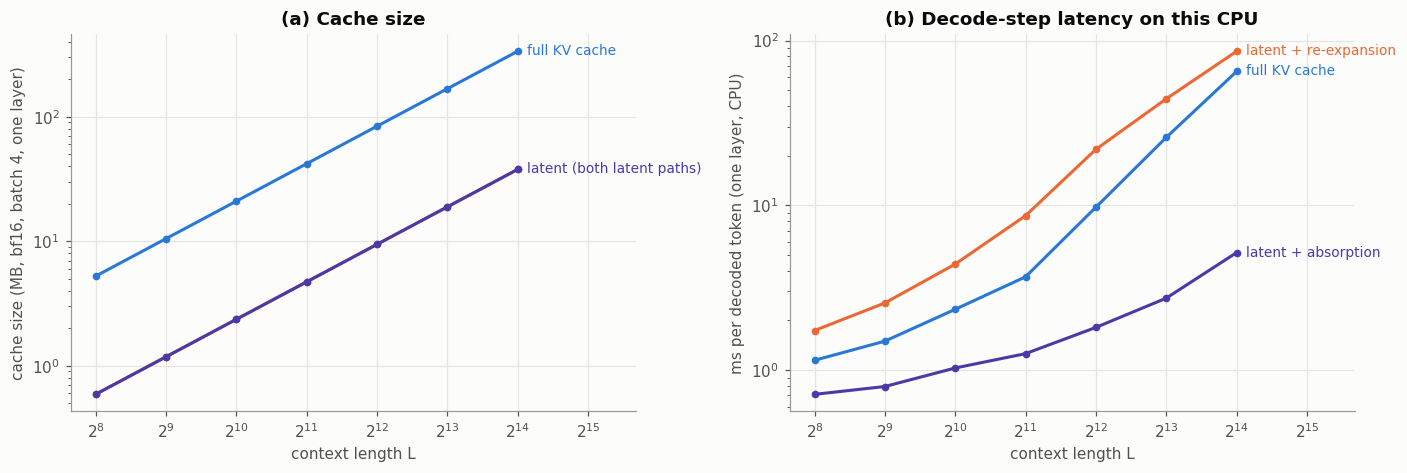

L=   256: full KV cache    1.14 ms  latent + re-expansion    1.74 ms  latent + absorption    0.71 ms
L=   512: full KV cache    1.50 ms  latent + re-expansion    2.55 ms  latent + absorption    0.79 ms
L=  1024: full KV cache    2.33 ms  latent + re-expansion    4.39 ms  latent + absorption    1.03 ms
L=  2048: full KV cache    3.68 ms  latent + re-expansion    8.64 ms  latent + absorption    1.26 ms
L=  4096: full KV cache    9.73 ms  latent + re-expansion   21.83 ms  latent + absorption    1.81 ms
L=  8192: full KV cache   25.80 ms  latent + re-expansion   44.25 ms  latent + absorption    2.73 ms
L= 16384: full KV cache   64.85 ms  latent + re-expansion   85.98 ms  latent + absorption    5.16 ms


In [17]:
torch.manual_seed(0)
bench_cfg = dict(d_model=1024, n_heads=16, q_lora_rank=384, kv_lora_rank=256,
                 qk_nope_head_dim=64, qk_rope_head_dim=32, v_head_dim=64, max_seq_len=16384)
bench = MultiHeadLatentAttention(**bench_cfg).eval()
batch, contexts_b = 4, [256, 512, 1024, 2048, 4096, 8192, 16384]
timing = {m: [] for m in ["naive", "reexpand", "absorb"]}
cache_mb = {m: [] for m in timing}

def time_decode_step(mode, L, reps=10):
    cache = bench.new_cache(batch, L, mode)
    for t in cache.values():
        t.normal_()                                 # pretend the first L-1 tokens are already cached
    x_new = torch.randn(batch, 1, bench_cfg["d_model"])
    with torch.no_grad():
        bench(x_new, start_pos=L - 1, cache=cache, mode=mode)        # warm-up
        t0 = time.perf_counter()
        for _ in range(reps):
            bench(x_new, start_pos=L - 1, cache=cache, mode=mode)
    elapsed_ms = (time.perf_counter() - t0) / reps * 1e3
    return elapsed_ms, sum(t.numel() for t in cache.values()) * 2 / 1e6  # bf16-equivalent MB

for L in contexts_b:
    for mode in timing:
        ms, mb = time_decode_step(mode, L, reps=3 if mode == "reexpand" else 10)
        timing[mode].append(ms); cache_mb[mode].append(mb)

labels = {"naive": "full KV cache", "reexpand": "latent + re-expansion", "absorb": "latent + absorption"}
cols = {"naive": BLUE, "reexpand": ORANGE, "absorb": VIOLET}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.4))
for mode in timing:
    ax1.plot(contexts_b, cache_mb[mode], marker="o", markersize=4, color=cols[mode])
    ax2.plot(contexts_b, timing[mode], marker="o", markersize=4, color=cols[mode])
    ax2.text(contexts_b[-1] * 1.1, timing[mode][-1], labels[mode], color=cols[mode], va="center", fontsize=9)
ax1.text(contexts_b[-1] * 1.1, cache_mb["naive"][-1], labels["naive"], color=cols["naive"], va="center", fontsize=9)
ax1.text(contexts_b[-1] * 1.1, cache_mb["absorb"][-1], "latent (both latent paths)", color=cols["absorb"], va="center", fontsize=9)
for ax in (ax1, ax2):
    ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xlim(200, 16384 * 3.2)
    ax.set_xlabel("context length L")
ax1.set_ylabel("cache size (MB, bf16, batch 4, one layer)"); ax1.set_title("(a) Cache size")
ax2.set_ylabel("ms per decoded token (one layer, CPU)"); ax2.set_title("(b) Decode-step latency on this CPU")
plt.tight_layout(); plt.show()

for i, L in enumerate(contexts_b):
    print(f"L={L:>6}: " + "  ".join(f"{labels[m]} {timing[m][i]:7.2f} ms" for m in timing))

**Reading the benchmark.** The cache-size panel is exact arithmetic: the latent cache is $\frac{16 \cdot (96 + 64)}{256 + 32} \approx 8.9\times$ smaller here. On the latency panel:
* **Re-expansion** is the slowest path. It saves memory but repeats the up-projection over the whole prefix at every step. This is the cost that absorption removes.
* **Absorption** is the fastest path on this machine at every context length, and the gap widens with $L$. Even on a CPU, streaming the 9× smaller cache outweighs the extra FLOPs per cached token. The exact ratios depend on the hardware's balance of compute and memory bandwidth (rerun the cell to see yours).
* On a GPU, where decode attention is strongly memory-bound, the smaller cache also allows much larger batches. DeepSeek-V2 reports 5.76× higher maximum generation throughput than DeepSeek 67B.

# 9. Parameter counts at DeepSeek-V3 scale

MLA is not just a cache trick. Because of the low-rank factorizations it also has **fewer parameters** than an MHA layer with the same head layout. We can instantiate both at full DeepSeek-V3 size on PyTorch's `meta` device: the parameters get shapes but no memory, so counting is free.

MLA (DeepSeek-V3 shape):
   wq_a              11.01 M
   q_norm.gain        0.00 M
   wq_b              37.75 M
   wkv_a              4.13 M
   kv_norm.gain       0.00 M
   wkv_b             16.78 M
   wo               117.44 M
   total            187.11 M
MHA with 128 heads x 128 dims: 469.76 M


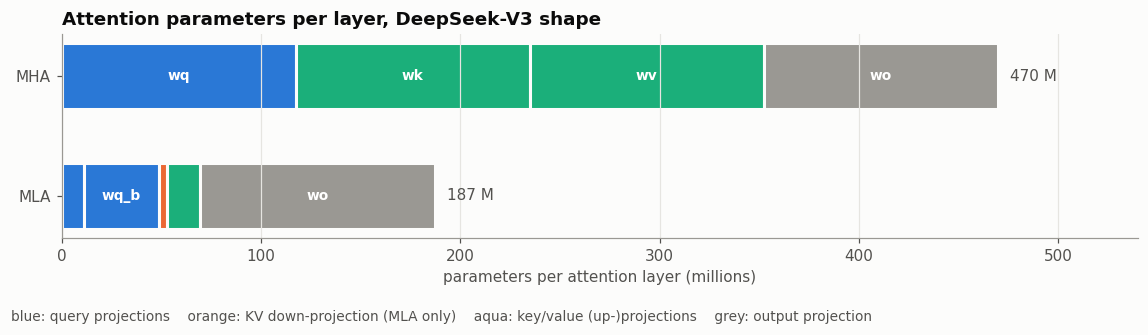

In [18]:
with torch.device("meta"):
    mla_v3 = MultiHeadLatentAttention(d_model=7168, n_heads=128, q_lora_rank=1536, kv_lora_rank=512,
                                      qk_nope_head_dim=128, qk_rope_head_dim=64, v_head_dim=128, max_seq_len=8)
    mha_v3 = GroupedQueryAttention(d_model=7168, n_heads=128, n_kv_heads=128, head_dim=128)

def count(mod):
    return {n.removesuffix(".weight"): p.numel() for n, p in mod.named_parameters()}

mla_counts, mha_counts = count(mla_v3), count(mha_v3)
print("MLA (DeepSeek-V3 shape):")
for n, c in mla_counts.items():
    print(f"   {n:<14} {c / 1e6:8.2f} M")
print(f"   {'total':<14} {sum(mla_counts.values()) / 1e6:8.2f} M")
print(f"MHA with 128 heads x 128 dims: {sum(mha_counts.values()) / 1e6:.2f} M")

role_color = {"wq": BLUE, "wq_a": BLUE, "wq_b": BLUE, "wk": AQUA, "wv": AQUA, "wkv_a": ORANGE, "wkv_b": AQUA, "wo": MUTED}
fig, ax = plt.subplots(figsize=(10.5, 3.0))
for y, (name, counts) in enumerate([("MLA", mla_counts), ("MHA", mha_counts)]):
    left = 0
    for n, c in counts.items():
        if n not in role_color:
            continue  # RMSNorm gains are negligible
        ax.barh(y, c / 1e6, left=left, color=role_color[n], edgecolor="#fcfcfb", linewidth=2, height=0.55)
        if c / 1e6 > 30:
            ax.text(left + c / 2e6, y, n, ha="center", va="center", color="white", fontsize=9, fontweight="bold")
        left += c / 1e6
    ax.text(left + 6, y, f"{left:.0f} M", va="center", color=INK_2)
ax.set_yticks([0, 1], ["MLA", "MHA"]); ax.grid(axis="y", visible=False); ax.set_xlim(0, 540)
ax.set_xlabel("parameters per attention layer (millions)")
ax.set_title("Attention parameters per layer, DeepSeek-V3 shape", loc="left")
fig.text(0.01, 0.01, "blue: query projections    orange: KV down-projection (MLA only)    aqua: key/value (up-)projections    grey: output projection",
         color=INK_2, fontsize=9)
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

# 10. MLA in production models

Every number below comes from the papers or the released `config.json` files. For the Kimi Linear and Kimi K3 rows, "layers" counts only the MLA layers; the rest are KDA.

| model | $d$ | layers | $n_h$ | $d_h$ | $d_h^R$ | $d_c$ (KV latent) | $d_c'$ (Q latent) | positional encoding |
|---|---|---|---|---|---|---|---|---|
| DeepSeek-V2 | 5120 | 60 | 128 | 128 | 64 | 512 | 1536 | decoupled RoPE (+YaRN on $k^R$) |
| DeepSeek-V2-Lite | 2048 | 27 | 16 | 128 | 64 | 512 | none | decoupled RoPE |
| DeepSeek-V3 | 7168 | 61 | 128 | 128 | 64 | 512 | 1536 | decoupled RoPE (+YaRN on $k^R$) |
| Kimi K2 | 7168 | 61 | 64 | 128 | 64 | 512 | 1536 | decoupled RoPE |
| Kimi Linear (48B-A3B) | 2304 | 7 of 27 | 32 | 128 | 64 | 512 | none | **NoPE** |
| Kimi K3 | 7168 | 24 of 93 | 96 | 128 | 64 | 512 | 1536 | **NoPE**, plus an output gate |

A few details that are easy to get wrong:
* **Concatenation order** is `[content ; rope]` in both the query and the key, and the softmax scale is $1/\sqrt{d_h + d_h^R} = 1/\sqrt{192}$, not $1/\sqrt{128}$.
* `kv_norm` is applied to the latent **before** it is cached, and $k^R$ is cached **after** rotation.
* For long context, DeepSeek-V3 applies YaRN to the decoupled key only and multiplies the softmax scale by $(0.1 \ln s + 1)^2$ with $s = 40$ (the code uses `mscale = 0.1 * mscale * ln(rope_factor) + 1`, squared). The V2 paper states the coefficient as 0.0707, the V3 paper and code as 0.1.
* **Kimi Linear uses MLA without any positional encoding (NoPE).** Its KDA layers carry all positional information. Without RoPE, the whole key is rotation-free, so the entire attention can be absorbed. The Kimi Linear paper notes that NoPE *"enables their conversion to the highly-efficient pure Multi-Query Attention (MQA) during inference"* and avoids RoPE retuning (frequency base, YaRN) for long context. See `26_kimi_delta_attention.ipynb` for the KDA side of that hybrid.

### Key takeaways
1. **Cache a latent, not keys and values.** One $d_c$-vector per token, plus a 64-dim shared RoPE key, instead of $2 n_h d_h$ numbers: 576 vs 32,768 elements per token per layer for DeepSeek-V3.
2. **Absorption makes the latent cache fast.** Fold $W^{UK}$ into the query and $W^{UV}$ into the output. Every head reads the same latent, so at inference time MLA behaves like MQA with a 576-dim key and a 512-dim value.
3. **RoPE must be decoupled.** Position-dependent rotations cannot be absorbed, so position lives in a small separate key that is cached already rotated.
4. **Bytes for FLOPs.** Compared with caching the full per-head keys and values (§8), absorption does ~3.4× more attention FLOPs but reads ~71× fewer bytes per generated token, a good trade for memory-bound decoding.

### Further reading
* **DeepSeek-V2 paper, §2.1 and Appendix C**: the original derivation, including the absorption argument and Table 1's cache comparison. https://arxiv.org/abs/2405.04434
* **"MLA: Redefining KV-Cache Through Low-Rank Projections and On-Demand Decompression"** (Hugging Face community blog): a readable walk-through of compression, decompression and decoupled RoPE with a runnable implementation. https://huggingface.co/blog/NormalUhr/mla-explanation
* **Verda (formerly DataCrunch) blog on MLA and weight absorption in SGLang**: good diagrams of the score and output computations under weight absorption, plus measured H200 decode speeds for the uncompressed, compressed and absorbed variants (the GPU version of our §8 benchmark). https://verda.com/blog/deepseek-sglang-multi-head-latent-attention
* **DeepSeek-V3 inference code** (`inference/model.py`, class `MLA`): the production absorbed path. With both run in float64, the module above matches it to ~1e-16. https://github.com/deepseek-ai/DeepSeek-V3